# Fashion-MNIST: clasificación de imágenes con redes neuronales

**Problema de visión por computadora:** reconocer qué prenda aparece en una imagen en escala de grises de 28×28 píxeles. Hay 10 clases.

**Objetivo de la tarea:**
- Usar `Flatten`.
- Graficar en 2D.
- Probar al menos 3 configuraciones.
- Medir el accuracy.

**Configuraciones:**

| Config | Arquitectura | Idea |
| --- | --- | --- |
| A | `Flatten` → `Dense(128)` | Red densa mínima (línea base) |
| B | `Flatten` → `Dense(256)` → `Dense(128)` con `Dropout` | Red densa más profunda y regularizada |
| C | `Conv2D` → `MaxPool` → `Conv2D` → `MaxPool` → `Flatten` → `Dense(128)` | Red convolucional (CNN): aprende bordes y texturas antes de aplanar |

## 1. Imports

In [1]:
import os
import warnings

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"   # oculta los avisos internos de TensorFlow
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(42)
np.random.seed(42)
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 2. Carga del dataset

In [2]:
train_ds, test_ds = tfds.load(
    'fashion_mnist',
    split=['train', 'test'],
    shuffle_files=True,
    as_supervised=True,
    batch_size=32,
)

CLASES = ["Camiseta", "Pantalón", "Suéter", "Vestido", "Abrigo",
          "Sandalia", "Camisa", "Tenis", "Bolsa", "Botín"]

## 3. Preprocesamiento

Los píxeles vienen como enteros de 0 a 255. Se escalan a valores de 0 a 1 para que la red entrene de forma estable.

In [3]:
def normalizar(imagen, etiqueta):
    return tf.cast(imagen, tf.float32) / 255.0, etiqueta

train = train_ds.map(normalizar).cache().prefetch(tf.data.AUTOTUNE)
test = test_ds.map(normalizar).cache().prefetch(tf.data.AUTOTUNE)

# Un lote de ejemplo para graficar (sin pasar por la caché)
imagenes, etiquetas = next(iter(train_ds.map(normalizar)))
imagenes.shape, etiquetas.shape

(TensorShape([32, 28, 28, 1]), TensorShape([32]))

## 4. Gráfica 2D: las imágenes

Cada imagen es una matriz 2D de 28×28 píxeles.

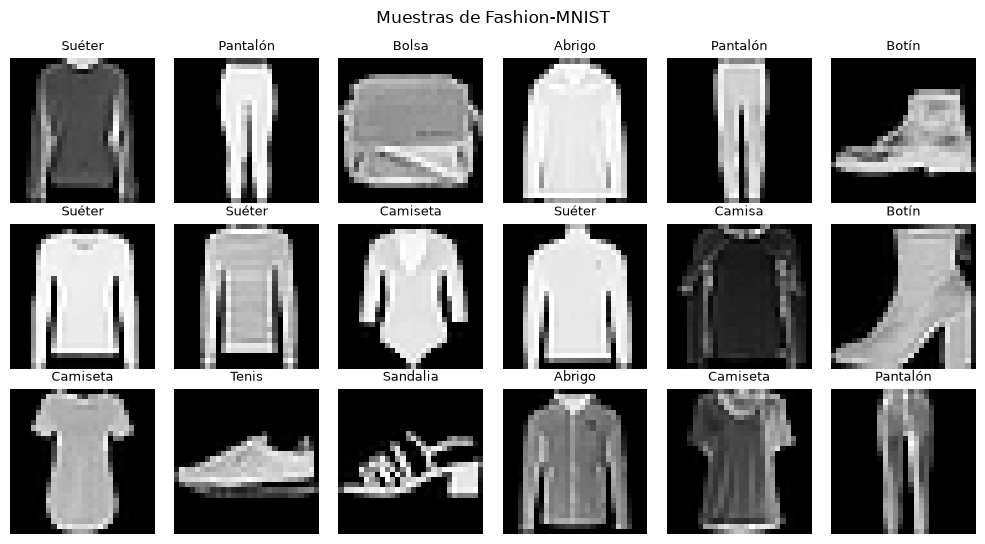

In [4]:
fig, axes = plt.subplots(3, 6, figsize=(10, 5.5))
for ax, img, lab in zip(axes.flat, imagenes, etiquetas):
    ax.imshow(img[:, :, 0], cmap="gray")
    ax.set_title(CLASES[int(lab)], fontsize=9)
    ax.axis("off")
plt.suptitle("Muestras de Fashion-MNIST")
plt.tight_layout()
plt.show()

## 5. Qué hace `Flatten`

Una capa densa recibe un vector, no una matriz. `Flatten` convierte la imagen de 28×28 (2D) en una fila de 784 valores (1D).

- **Costo:** la red densa pierde la información de qué píxeles son vecinos.
- **Ventaja de la CNN:** primero procesa la imagen en 2D con filtros, y aplana hasta el final.

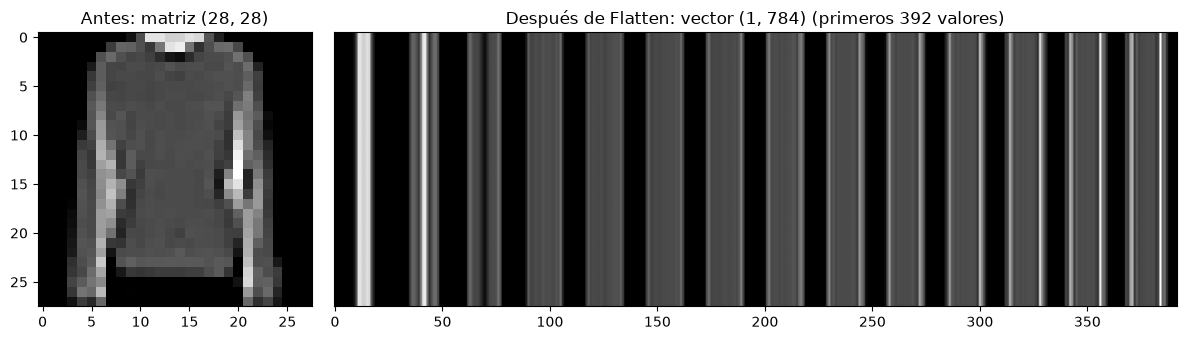

In [5]:
img = imagenes[0, :, :, 0].numpy()
plana = layers.Flatten()(imagenes[:1]).numpy()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.5), gridspec_kw={"width_ratios": [1, 3]})
ax1.imshow(img, cmap="gray")
ax1.set_title(f"Antes: matriz {img.shape}")
ax2.imshow(plana[:, :392].reshape(1, -1).repeat(40, axis=0), cmap="gray", aspect="auto")
ax2.set_title(f"Después de Flatten: vector {plana.shape} (primeros 392 valores)")
ax2.set_yticks([])
plt.tight_layout()
plt.show()

## 6. Las 3 configuraciones

In [6]:
def config_a():
    return keras.Sequential([
        keras.Input(shape=(28, 28, 1)),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ], name="A_densa_simple")


def config_b():
    return keras.Sequential([
        keras.Input(shape=(28, 28, 1)),
        layers.Flatten(),
        layers.Dense(256, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(10, activation="softmax"),
    ], name="B_densa_profunda")


def config_c():
    return keras.Sequential([
        keras.Input(shape=(28, 28, 1)),
        layers.Conv2D(32, 3, activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation="relu"),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(10, activation="softmax"),
    ], name="C_convolucional")


CONFIGS = [config_a, config_b, config_c]

for crear in CONFIGS:
    m = crear()
    print(f"{m.name:18} parámetros: {m.count_params():,}")

A_densa_simple     parámetros: 101,770
B_densa_profunda   parámetros: 235,146
C_convolucional    parámetros: 225,034


## 7. Entrenamiento

Mismas condiciones para las tres configuraciones, para que la comparación sea justa:
- Optimizador Adam.
- Pérdida `sparse_categorical_crossentropy`: las etiquetas son enteros del 0 al 9.
- 8 épocas.
- Métrica: **accuracy**.

In [7]:
EPOCAS = 8
historiales, modelos, resultados = {}, {}, {}

for crear in CONFIGS:
    modelo = crear()
    modelo.compile(optimizer="adam",
                   loss="sparse_categorical_crossentropy",
                   metrics=["accuracy"])
    print(f"\n=== {modelo.name} ===")
    h = modelo.fit(train, validation_data=test, epochs=EPOCAS, verbose=2)
    _, acc = modelo.evaluate(test, verbose=0)

    historiales[modelo.name] = h.history
    modelos[modelo.name] = modelo
    resultados[modelo.name] = acc


=== A_densa_simple ===
Epoch 1/8


1875/1875 - 2s - 1ms/step - accuracy: 0.8243 - loss: 0.4940 - val_accuracy: 0.8379 - val_loss: 0.4548


Epoch 2/8


1875/1875 - 1s - 551us/step - accuracy: 0.8648 - loss: 0.3732 - val_accuracy: 0.8517 - val_loss: 0.4093


Epoch 3/8


1875/1875 - 1s - 516us/step - accuracy: 0.8781 - loss: 0.3340 - val_accuracy: 0.8626 - val_loss: 0.3785


... (38 outputs left out)

Epoch 7/8


1875/1875 - 6s - 3ms/step - accuracy: 0.9263 - loss: 0.1981 - val_accuracy: 0.9034 - val_loss: 0.2744


Epoch 8/8


1875/1875 - 6s - 3ms/step - accuracy: 0.9316 - loss: 0.1817 - val_accuracy: 0.9076 - val_loss: 0.2753


## 8. Gráfica 2D: accuracy por época

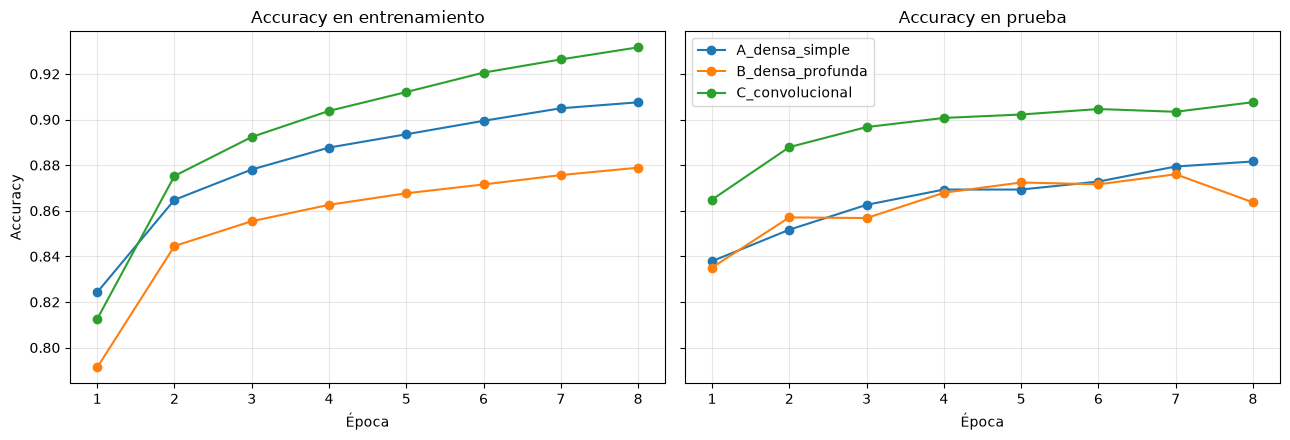

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for nombre, h in historiales.items():
    epocas = range(1, len(h["accuracy"]) + 1)
    ax1.plot(epocas, h["accuracy"], marker="o", label=nombre)
    ax2.plot(epocas, h["val_accuracy"], marker="o", label=nombre)

ax1.set_title("Accuracy en entrenamiento")
ax2.set_title("Accuracy en prueba")
for ax in (ax1, ax2):
    ax.set_xlabel("Época")
    ax.grid(alpha=0.3)
ax1.set_ylabel("Accuracy")
ax2.legend()
plt.tight_layout()
plt.show()

## 9. Comparación final

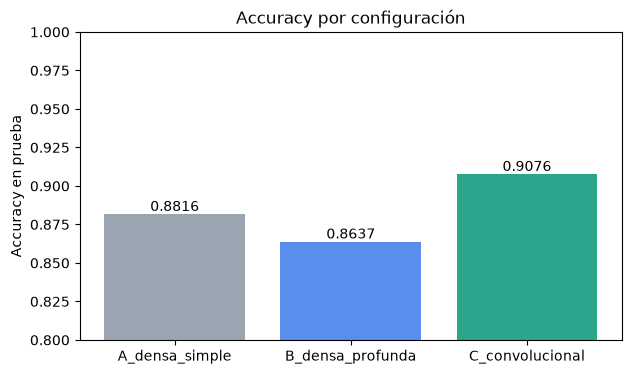

C_convolucional    0.9076
A_densa_simple     0.8816
B_densa_profunda   0.8637


In [9]:
nombres = list(resultados)
accs = [resultados[n] for n in nombres]

plt.figure(figsize=(7, 4))
barras = plt.bar(nombres, accs, color=["#9aa5b1", "#5b8def", "#2ca58d"])
plt.bar_label(barras, labels=[f"{a:.4f}" for a in accs])
plt.ylim(0.8, 1.0)
plt.ylabel("Accuracy en prueba")
plt.title("Accuracy por configuración")
plt.show()

for n in sorted(resultados, key=resultados.get, reverse=True):
    print(f"{n:18} {resultados[n]:.4f}")

## 10. Análisis del mejor modelo

### Matriz de confusión

Muestra qué clases confunde el modelo entre sí.

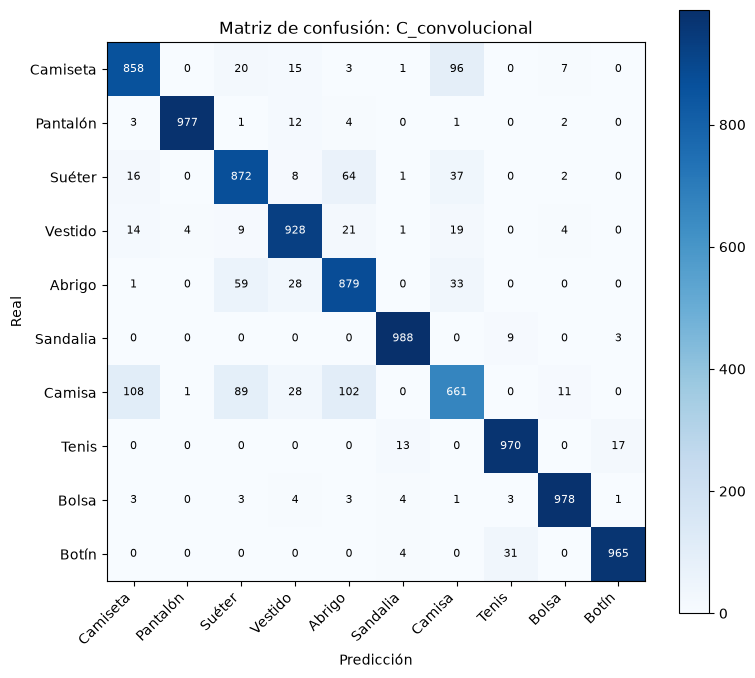

In [10]:
mejor_nombre = max(resultados, key=resultados.get)
mejor = modelos[mejor_nombre]

y_real = np.concatenate([y.numpy() for _, y in test])
y_pred = mejor.predict(test, verbose=0).argmax(axis=1)
matriz = tf.math.confusion_matrix(y_real, y_pred).numpy()

plt.figure(figsize=(8, 7))
plt.imshow(matriz, cmap="Blues")
plt.colorbar()
plt.xticks(range(10), CLASES, rotation=45, ha="right")
plt.yticks(range(10), CLASES)
for i in range(10):
    for j in range(10):
        plt.text(j, i, matriz[i, j], ha="center", va="center",
                 color="white" if matriz[i, j] > matriz.max() / 2 else "black", fontsize=8)
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title(f"Matriz de confusión: {mejor_nombre}")
plt.tight_layout()
plt.show()

### Predicciones: verde = acierto, rojo = error

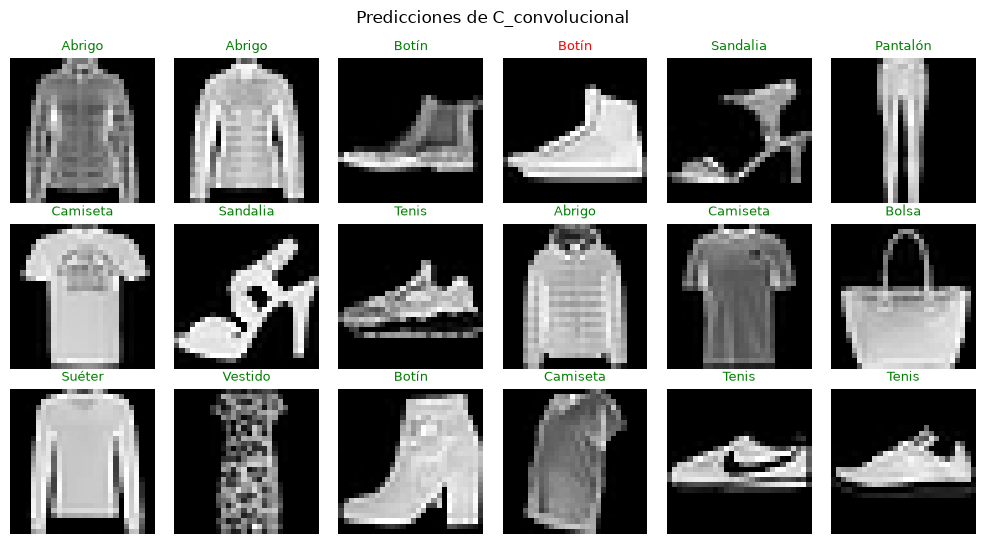

In [11]:
imgs_test, etiq_test = next(iter(test_ds.map(normalizar)))
pred = mejor.predict(imgs_test, verbose=0).argmax(axis=1)

fig, axes = plt.subplots(3, 6, figsize=(10, 5.5))
for ax, img, real, p in zip(axes.flat, imgs_test, etiq_test.numpy(), pred):
    ax.imshow(img[:, :, 0], cmap="gray")
    ax.set_title(CLASES[p], fontsize=9, color="green" if p == real else "red")
    ax.axis("off")
plt.suptitle(f"Predicciones de {mejor_nombre}")
plt.tight_layout()
plt.show()

### Gráfica 2D: lo que la red aprendió

Se toma la salida de la penúltima capa densa (128 valores por imagen) y se proyecta a 2 dimensiones con PCA. Si la red aprendió bien, las imágenes de la misma clase quedan agrupadas.

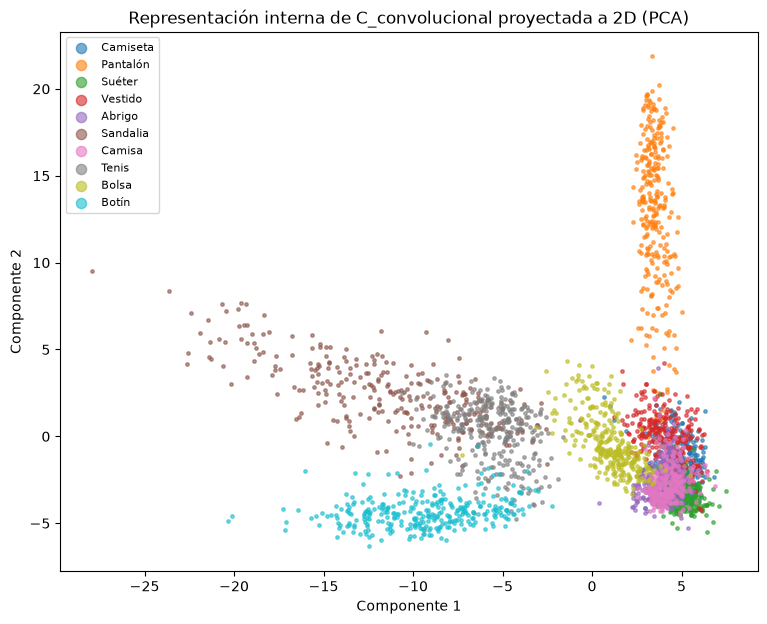

In [12]:
extractor = keras.Model(inputs=mejor.inputs, outputs=mejor.layers[-3].output)

X_emb = extractor.predict(test, verbose=0)[:3000]
y_emb = y_real[:3000]

# PCA con numpy: centrar y proyectar sobre las 2 direcciones de mayor varianza
centrado = X_emb - X_emb.mean(axis=0)
_, _, Vt = np.linalg.svd(centrado, full_matrices=False)
puntos = centrado @ Vt[:2].T

plt.figure(figsize=(9, 7))
for c in range(10):
    sel = y_emb == c
    plt.scatter(puntos[sel, 0], puntos[sel, 1], s=6, alpha=0.6, label=CLASES[c])
plt.legend(markerscale=3, fontsize=8)
plt.xlabel("Componente 1")
plt.ylabel("Componente 2")
plt.title(f"Representación interna de {mejor_nombre} proyectada a 2D (PCA)")
plt.show()

## 11. Conclusiones

- **La red convolucional (C) fue la mejor, con alrededor de 0.91 de accuracy,** contra 0.86–0.88 de las dos redes densas. En visión por computadora conviene procesar la imagen en 2D antes de aplanarla: los filtros convolucionales detectan bordes y texturas sin importar en qué parte de la imagen estén.
- **Hacer más grande la red densa (B) no mejoró el accuracy:** quedó igual o por debajo de la A, teniendo más del doble de parámetros, y su accuracy en prueba oscila de una época a otra. El problema no es el tamaño, sino que `Flatten` al inicio tira la información espacial.
- **`Dropout` redujo el sobreajuste:** la red A llega a ~0.91 en entrenamiento pero ~0.88 en prueba, una brecha de casi 3 puntos. En la B, con `Dropout`, la brecha baja a alrededor de 1.5 puntos. Con solo 8 épocas, esa regularización todavía no se traduce en más accuracy.
- **La clase más difícil es Camisa:** se confunde con Camiseta, Suéter y Abrigo, que tienen siluetas muy parecidas en 28×28 píxeles. El calzado (Sandalia, Tenis y Botín) casi nunca se confunde con la ropa.
- **La proyección 2D lo confirma:** el calzado forma un grupo separado, Pantalón y Bolsa quedan aislados, y las prendas de la parte superior se enciman en la misma zona.